# 07 · A phoneme decoder on TIMIT: soft staircase vs STE on speech

The speech starter. A small CTC phoneme recognizer on TIMIT (630 speakers, 39 phones), small enough to train in a few
minutes, used exactly like the tiny LM of notebook 06: float baseline → PTQ → QAT contenders under one budget.

| Step | What you will see |
|---|---|
| 1 | data: TIMIT log-mel features and phone sequences |
| 2 | CTC in two equations |
| 3 | the model and its float baseline (phone error rate, PER) |
| 4 | PTQ: uniform / equal-probability / Lloyd-Max |
| 5 | QAT contenders at 3 and 2 bits |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

> 📘 TIMIT phoneme recognition with CTC and phone error rate is a classic **common-practice** benchmark (Graves et al.
> 2006, doi:10.1145/1143844.1143891). Our split is speaker-disjoint but not the official one (see Step 1).

Data path: `TIMIT_ROOT` (default `/extra/cadrete/database/data/asr_en`, which holds `wav/full-timit`,
frame-level labels in `ilabel/full-timit` and `lst/ph.list`). Features are cached in `data/` after the first run.

In [1]:
import os, sys, copy, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from vvtk_quant import VVTK_QModel
from common_seq import (DEVICE, OUT, timit_features, timit_split, timit_phones, PhoneCTC, ctc_per,
                        ctc_train_epoch, ctc_batches, cosine)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Step 1 · Data

Each utterance becomes 40 log-mel coefficients every 10 ms. TIMIT's frame labels are collapsed into the phone
sequence (silences removed): that is the CTC target. The split is **speaker-disjoint** (10 % of speakers held out) and
drops the two SA sentences that every speaker reads. This is *not* the official core test set, so numbers are not
comparable with the literature; it is fine for comparing quantizers with each other.

6299 utterances; train 4535, test 504; CTC vocabulary 40 (blank + 39 phones)


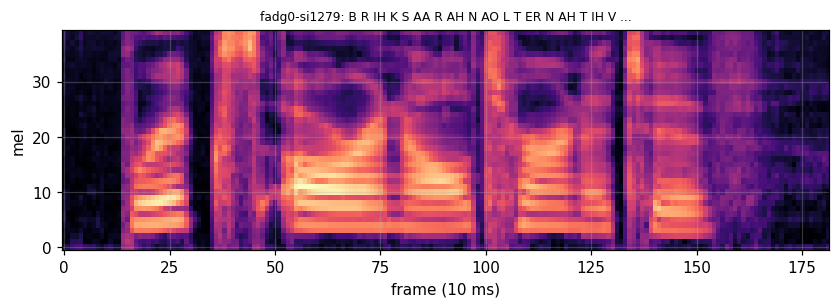

In [2]:
d = timit_features()
train_idx, test_idx = timit_split(d)
ph, vocab = timit_phones()
allf = torch.cat([d["feats"][i].float() for i in train_idx[:1000]])
MEAN, STD = allf.mean(0).to(DEVICE), allf.std(0).to(DEVICE)
print(f"{len(d['names'])} utterances; train {len(train_idx)}, test {len(test_idx)}; CTC vocabulary {len(vocab)} (blank + 39 phones)")
i = train_idx[0]
plt.figure(figsize=(9, 2.6)); plt.imshow(d["feats"][i].float().T, origin="lower", aspect="auto", cmap="magma")
plt.title(d["names"][i] + ": " + " ".join(vocab[p] for p in d["labels"][i][:25].tolist()) + " ...", fontsize=8)
plt.xlabel("frame (10 ms)"); plt.ylabel("mel"); plt.show()

## Step 2 · CTC in two equations

The encoder outputs, for every frame $t$, a distribution $p_t(k)$ over the 39 phones and a **blank**. An *alignment*
$\pi = (\pi_1,\dots,\pi_T)$ is mapped to a phone sequence by $\mathcal{B}$: merge repeats, then drop blanks
($\texttt{a a - b - b} \mapsto \texttt{a b b}$). CTC maximises the probability of the target $y$ summed over all
alignments:

$$\mathcal{L}_{\text{CTC}} = -\log \sum_{\pi:\, \mathcal{B}(\pi) = y} \ \prod_{t=1}^{T} p_t(\pi_t)$$

(computed by dynamic programming in `F.ctc_loss`). Greedy decoding takes $\arg\max_k p_t(k)$ per frame and applies
$\mathcal{B}$. The metric is the **phone error rate**, $\text{PER} = (S + D + I)/N$ from the edit distance to the
reference.

## Step 3 · Model and float baseline

Two `Conv1d` layers (the second one halves the frame rate to 20 ms), 4 transformer blocks ($d=192$, RoPE), a linear
CTC head: about 2 M parameters, all in `Conv1d`/`Linear` layers that vvtk_quant can quantize.
40 epochs of AdamW with warm-up + cosine. Cached in `out/`.

In [3]:
torch.manual_seed(0)
model = PhoneCTC(n_in=40, n_out=len(vocab)).to(DEVICE)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")
EPOCHS = 40
ckpt = os.path.join(OUT, f"phonectc_fp32_e{EPOCHS}.pth")
if os.path.exists(ckpt):
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); print("loaded", ckpt)
else:
    steps = EPOCHS * len(list(ctc_batches(d, train_idx, shuffle=False)))
    opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=0.01)
    sched = cosine(opt, steps, warmup=500)
    t0 = time.time()
    for ep in range(EPOCHS):
        loss = ctc_train_epoch(model, d, train_idx, opt, MEAN, STD, sched, seed=ep)
        if (ep + 1) % 5 == 0:
            print(f"epoch {ep + 1:>2}: ctc {loss:.3f}  test PER {ctc_per(model, d, test_idx, MEAN, STD):.2f}%  ({time.time() - t0:.0f}s)")
    torch.save(model.state_dict(), ckpt)
per_fp32 = ctc_per(model, d, test_idx, MEAN, STD)
print(f"fp32 test PER: {per_fp32:.2f}%")

parameters: 2.01 M


epoch  5: ctc 1.106  test PER 33.86%  (25s)


epoch 10: ctc 0.653  test PER 27.26%  (50s)


epoch 15: ctc 0.375  test PER 25.21%  (75s)


epoch 20: ctc 0.196  test PER 24.01%  (98s)


epoch 25: ctc 0.092  test PER 23.59%  (120s)


epoch 30: ctc 0.040  test PER 23.08%  (143s)


epoch 35: ctc 0.023  test PER 22.58%  (165s)


epoch 40: ctc 0.019  test PER 22.75%  (187s)


fp32 test PER: 22.75%


## Step 4 · PTQ

Quantize every `Conv1d` and `Linear` (including the CTC head), no training.

 uniform: 8b  22.66%  6b  22.86%  4b  24.30%  3b  38.87%  2b 125.91%
  eqprob: 8b  22.55%  6b  22.78%  4b  24.35%  3b  27.12%  2b  37.84%
   lloyd: 8b  22.72%  6b  22.73%  4b  23.18%  3b  24.45%  2b  32.04%


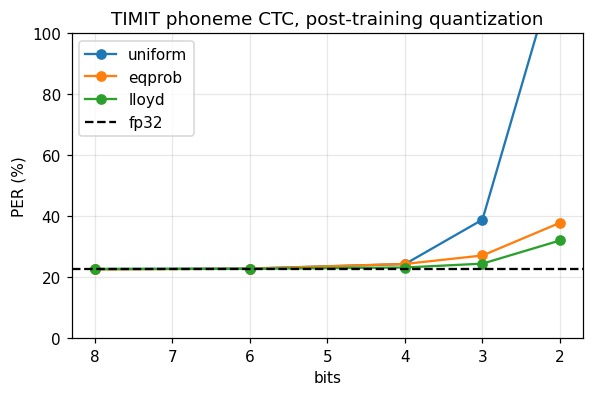

In [4]:
MT = [nn.Conv1d, nn.Linear]
def wrap(m, b, method, **kw):
    q = VVTK_QModel(copy.deepcopy(m), b=b, module_types=MT, **kw)
    q.calibrate_quant(method=method)
    return q

bits = [8, 6, 4, 3, 2]
ptq = {meth: [ctc_per(wrap(model, b, meth), d, test_idx, MEAN, STD) for b in bits] for meth in ["uniform", "eqprob", "lloyd"]}
for meth, v in ptq.items():
    print(f"{meth:>8}: " + "  ".join(f"{b}b {x:6.2f}%" for b, x in zip(bits, v)))
plt.figure(figsize=(6, 3.6))
for meth, v in ptq.items():
    plt.plot(bits, v, "o-", label=meth)
plt.axhline(per_fp32, color="k", ls="--", label="fp32")
plt.gca().invert_xaxis(); plt.ylim(0, 100); plt.xlabel("bits"); plt.ylabel("PER (%)")
plt.title("TIMIT phoneme CTC, post-training quantization"); plt.legend(); plt.show()

## Step 5 · QAT contenders

Same protocol as notebooks 04 and 06: from the float checkpoint, **8 more epochs** for everybody (AdamW
$3\cdot10^{-4}$, cosine), soft staircase $T: 2\to40$, fused anchor `"weight"` with $\lambda = 1$.

In [5]:
QEPOCHS, QLR, T0, T1 = 8, 3e-4, 2.0, 40.0
CONTENDERS = {
    "fp32":              None,
    "ste-uniform":       dict(mode="ste", method="uniform"),
    "ste-lloyd":         dict(mode="ste", method="lloyd"),
    "soft-lloyd":        dict(mode="soft", method="lloyd"),
    "soft-lloyd+anchor": dict(mode="soft", method="lloyd", anchor="weight", anchor_lambda=1.0),
}
steps_per_epoch = len(list(ctc_batches(d, train_idx, shuffle=False)))
total = QEPOCHS * steps_per_epoch

def qat(name, b):
    cfg = CONTENDERS[name]
    torch.manual_seed(0)
    if cfg is None:
        q = copy.deepcopy(model)
    else:
        cfg = dict(cfg); meth = cfg.pop("method")
        q = wrap(model, b, meth, temp=T0, **cfg)
    opt = torch.optim.AdamW(q.parameters(), QLR, weight_decay=0.0)
    sched = cosine(opt, total)
    step = [0]
    def hook():
        if cfg is not None and cfg["mode"] == "soft":
            q.update_temp(T0 * (T1 / T0) ** (step[0] / (total - 1)))
        step[0] += 1
    curve = [ctc_per(q, d, test_idx, MEAN, STD)]
    for ep in range(QEPOCHS):
        ctc_train_epoch(q, d, train_idx, opt, MEAN, STD, sched, step_hook=hook, seed=100 + ep)
        if (ep + 1) % 2 == 0:
            curve.append(ctc_per(q, d, test_idx, MEAN, STD))
    tag = "float  " if cfg is None else f"{b}-bit:"
    print(f"  {name:<18} {tag} PER {curve[0]:6.2f}% (PTQ) -> {curve[-1]:6.2f}% (QAT)")
    return curve

R = {}
for b in [3, 2]:
    for name in CONTENDERS:
        if name == "fp32" and ("fp32", 3) in R:
            R[(name, b)] = R[("fp32", 3)]; continue
        R[(name, b)] = qat(name, b)

  fp32               3-bit: PER  22.75% (PTQ) ->  22.64% (QAT)


  ste-uniform        3-bit: PER  38.87% (PTQ) ->  23.76% (QAT)


  ste-lloyd          3-bit: PER  24.45% (PTQ) ->  23.04% (QAT)


  soft-lloyd         3-bit: PER  24.45% (PTQ) ->  23.30% (QAT)


  soft-lloyd+anchor  3-bit: PER  24.45% (PTQ) ->  23.82% (QAT)


  ste-uniform        2-bit: PER 125.91% (PTQ) ->  52.44% (QAT)


  ste-lloyd          2-bit: PER  32.04% (PTQ) ->  23.39% (QAT)


  soft-lloyd         2-bit: PER  32.04% (PTQ) ->  24.82% (QAT)


  soft-lloyd+anchor  2-bit: PER  32.04% (PTQ) ->  25.27% (QAT)


/tmp/ipykernel_4185484/3024076415.py:5: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(np.arange(len(c)) * 2, c, "o-", label=name, ls="--" if name == "fp32" else "-")


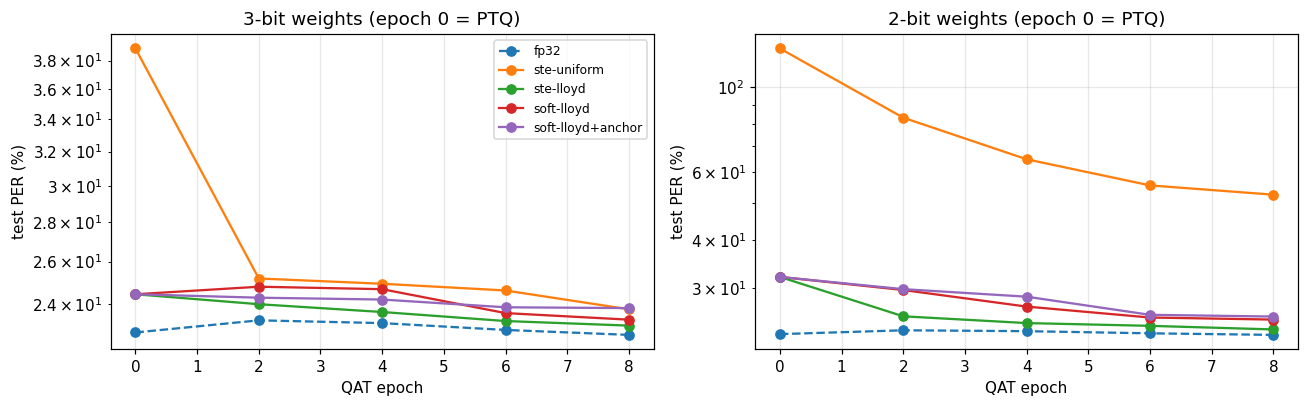

contender            |        3-bit PER |        2-bit PER   (PTQ -> QAT)
fp32                 |  22.75 ->  22.64 |  22.75 ->  22.64
ste-uniform          |  38.87 ->  23.76 | 125.91 ->  52.44
ste-lloyd            |  24.45 ->  23.04 |  32.04 ->  23.39
soft-lloyd           |  24.45 ->  23.30 |  32.04 ->  24.82
soft-lloyd+anchor    |  24.45 ->  23.82 |  32.04 ->  25.27


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, b in zip(axs, [3, 2]):
    for name in CONTENDERS:
        c = R[(name, b)]
        ax.plot(np.arange(len(c)) * 2, c, "o-", label=name, ls="--" if name == "fp32" else "-")
    ax.set_title(f"{b}-bit weights (epoch 0 = PTQ)"); ax.set_xlabel("QAT epoch"); ax.set_ylabel("test PER (%)")
    ax.set_yscale("log")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{'contender':<20} | {'3-bit PER':>16} | {'2-bit PER':>16}   (PTQ -> QAT)")
for name in CONTENDERS:
    print(f"{name:<20} | " + " | ".join(f"{R[(name, b)][0]:6.2f} -> {R[(name, b)][-1]:6.2f}" for b in [3, 2]))

### Reading the results (v1.0 run, one seed; the numbers are in the cells above)

* **PTQ: the same picture as the tiny LM.** At 3 bits, uniform PTQ costs 16 PER points (38.9 % vs 22.8 % float),
  equal-probability 4.4 points, Lloyd-Max 1.7. At 2 bits uniform is useless (PER above 100 % means the decoder
  *inserts* more phones than the reference has), Lloyd-Max is at 32 %.
* **QAT: STE on Lloyd levels is again the best quantized contender** (2-bit: 23.4 % vs 22.6 % for float after the
  same 8 epochs). Soft (24.8 %) and soft + anchor (25.3 %) recover most of the PTQ loss but less than STE-Lloyd.
  STE on a uniform grid stays at 52 %.
* **Two testbeds, one message so far:** the level placement (📘 Lloyd-Max) gives most of the gain; the 🧪 soft staircase
  and anchor, *with these schedules* ($T: 2\to40$, constant $\lambda=1$, 8 epochs), do not beat STE. That is the
  starting point of the study, not its conclusion: the schedules were not tuned, and one seed cannot separate
  differences of 1–2 PER points.
* **Overfitting again:** the float model reaches CTC loss 0.02 on train while test PER stalls at ~23 %. Regularization
  effects of quantization can hide or fake differences; use more data (LibriSpeech) before final claims.

### From here to your study
* Same caveats as notebook 06: one seed, short QAT. Report mean ± std over 3 seeds before comparing.
* Make the task harder before making the model bigger: word-level CTC on LibriSpeech-100 (the
  `2026_15_asr_multi` pipeline has one), then compress a pretrained Whisper-tiny/base.
* Quantize the activations too (the deployed CPU/FPGA model needs it): a natural next feature for vvtk_quant.